# E4 — Optimisation du seuil de décision COVID (validation)

**Sans réentraînement.** Charge le meilleur checkpoint de E4 fine-tuning phase 1, teste les seuils de 0,10 à 0,90 (pas de 0,05), compare à la règle d'origine et sauvegarde les courbes/CSV sur Drive.

Les seuils sont choisis **uniquement sur la validation**. Le jeu de test reste intact. Les sorties de ce notebook sont des analyses exploratoires, pas une estimation finale de performance.

**Attention** : si le runtime a été réinitialisé, réactiver la copie du dataset local (ou utiliser le ZIP).

In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

PROJECT_DIR = Path('/content/drive/MyDrive/Apprentissage/DS/projet')
DATASET_ROOT = Path('/content/COVID-19_Radiography_Dataset')
DRIVE_DATASET_ROOT = PROJECT_DIR / 'COVID-19_Radiography_Dataset'

# Copie facultative si les images locales ont disparu (décommenter au besoin).
if not DATASET_ROOT.exists():
     t0 = time.perf_counter()
     shutil.copytree(DRIVE_DATASET_ROOT, DATASET_ROOT)
     print('Copie en minutes :', (time.perf_counter() - t0)/60)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset absent : {DATASET_ROOT}. Décommenter la copie ci-dessus.')
print('GPU :', tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copie en minutes : 19.85260334656667
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
val_df = pd.read_csv(PROJECT_DIR / 'validation.csv')

def local_filepath(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin CSV inattendu : {original}')
    return str(DATASET_ROOT / normalized.split(marker, 1)[1])

val_df['filepath'] = val_df['filepath'].map(local_filepath)
assert len(val_df) == 3387, f'Nombre de lignes validation inattendu : {len(val_df)}'
assert val_df['filepath'].map(lambda p: Path(p).is_file()).all(), 'Images manquantes sur le disque local'
print('Images validation :', len(val_df))

Images validation : 3387


In [5]:
OUTPUT_DIR = PROJECT_DIR / 'E4_optimisation_seuil_COVID'
CHECKPOINT = PROJECT_DIR / 'E4_finetuning' / 'E4_FT_B5_LR1e-5_best.keras'
OUTPUT_DIR.mkdir(exist_ok=True)
assert CHECKPOINT.is_file(), f'Checkpoint introuvable : {CHECKPOINT}'
val_df['target'] = val_df['target'].astype(str)
val_generator = ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_dataframe(
    val_df, x_col='filepath', y_col='target', classes=['0','1'],
    target_size=(224,224), color_mode='rgb', class_mode='binary',
    batch_size=32, shuffle=False)
assert val_generator.class_indices == {'0': 0, '1': 1}
# Vérifier le mapping initial : target=1 doit bien représenter COVID.
print('Classes E4 :', val_generator.class_indices)
print('Répartition des cibles :', val_df['target'].value_counts().to_dict())
model = load_model(CHECKPOINT, compile=False)
val_generator.reset()
y_prob = np.asarray(model.predict(val_generator, verbose=1)).reshape(-1)
y_true = np.asarray(val_generator.classes, dtype=int)
assert len(y_prob) == len(y_true)
assert np.isfinite(y_prob).all() and np.all((y_prob >= 0) & (y_prob <= 1))
print('Probabilités COVID :', pd.Series(y_prob).describe())

def predict_at_threshold(t):
    return (y_prob >= t).astype(int)

baseline_pred = predict_at_threshold(0.5)
BASELINE_NAME = 'E4 seuil 0.50'


Found 3387 validated image filenames belonging to 2 classes.
Classes E4 : {'0': 0, '1': 1}
Répartition des cibles : {'0': 2808, '1': 579}
106/106 ━━━━━━━━━━━━━━━━━━━━ 21s 186ms/step
Probabilités COVID : count    3.387000e+03
mean     1.685254e-01
std      3.655929e-01
min      1.190489e-18
25%      2.546533e-08
50%      4.017313e-06
75%      1.865744e-03
max      1.000000e+00
dtype: float64


In [6]:
def metrics_for(pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=[1], average=None, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(precision_COVID=float(p[0]), recall_COVID=float(r[0]),
                f1_COVID=float(f1[0]), FP=int(fp), FN=int(fn), TP=int(tp), TN=int(tn))

thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
rows = [{'regle': f'seuil_{t:.2f}', 'seuil': float(t), **metrics_for(predict_at_threshold(t))}
        for t in thresholds]
results = pd.DataFrame(rows)
baseline = metrics_for(baseline_pred)
print('Règle initiale :', BASELINE_NAME, baseline)
print(results.to_string(index=False))
results.to_csv(OUTPUT_DIR / 'comparaison_seuils_validation.csv', index=False)
pd.DataFrame([{'regle': BASELINE_NAME, **baseline}]).to_csv(
    OUTPUT_DIR / 'baseline_validation.csv', index=False)

# Deux propositions explicites, sans toucher au test :
# 1) meilleur F1 COVID ; 2) meilleur recall parmi les seuils gardant
#    une précision COVID au moins égale à celle de la baseline.
max_f1 = results.sort_values(['f1_COVID','recall_COVID'], ascending=False).iloc[0]
eligible = results[results['precision_COVID'] >= baseline['precision_COVID']]
max_recall_constrained = (eligible.sort_values(['recall_COVID','f1_COVID'], ascending=False).iloc[0]
                          if len(eligible) else None)
print('\nMeilleur F1 :', max_f1[['seuil','precision_COVID','recall_COVID','f1_COVID','FN','FP']].to_dict())
print('Meilleur rappel avec précision >= baseline :',
      None if max_recall_constrained is None else
      max_recall_constrained[['seuil','precision_COVID','recall_COVID','f1_COVID','FN','FP']].to_dict())


Règle initiale : E4 seuil 0.50 {'precision_COVID': 0.9754385964912281, 'recall_COVID': 0.9602763385146805, 'f1_COVID': 0.9677980852915579, 'FP': 14, 'FN': 23, 'TP': 556, 'TN': 2794}
     regle  seuil  precision_COVID  recall_COVID  f1_COVID  FP  FN  TP   TN
seuil_0.10   0.10         0.926710      0.982729  0.953898  45  10 569 2763
seuil_0.15   0.15         0.941957      0.981002  0.961083  35  11 568 2773
seuil_0.20   0.20         0.956007      0.975820  0.965812  26  14 565 2782
seuil_0.25   0.25         0.957627      0.975820  0.966638  25  14 565 2783
seuil_0.30   0.30         0.965636      0.970639  0.968131  20  17 562 2788
seuil_0.35   0.35         0.972270      0.968912  0.970588  16  18 561 2792
seuil_0.40   0.40         0.972222      0.967185  0.969697  16  19 560 2792
seuil_0.45   0.45         0.972174      0.965458  0.968804  16  20 559 2792
seuil_0.50   0.50         0.975439      0.960276  0.967798  14  23 556 2794
seuil_0.55   0.55         0.976991      0.953368  0.965035

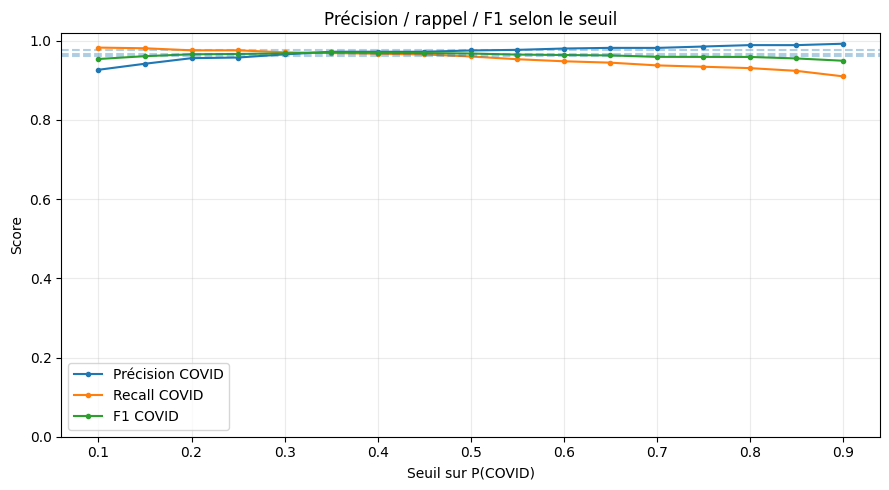

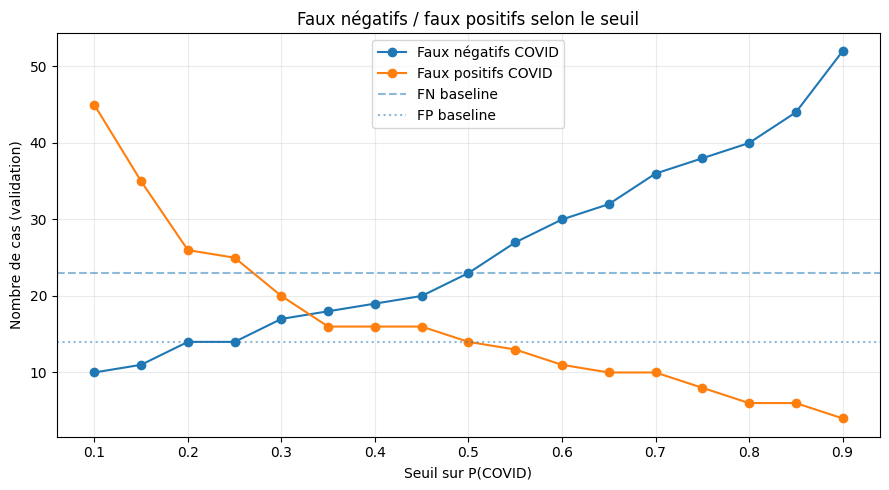

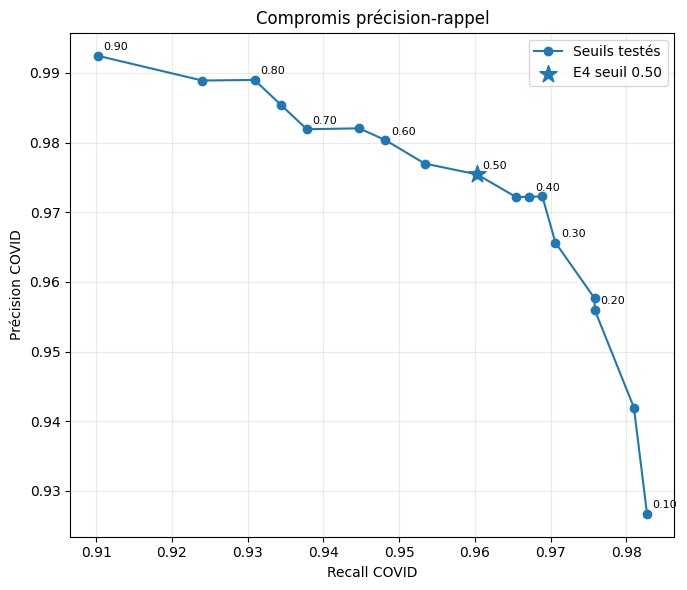

Résultats enregistrés dans : /content/drive/MyDrive/Apprentissage/DS/projet/E4_optimisation_seuil_COVID


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric, label in [('precision_COVID','Précision COVID'),
                      ('recall_COVID','Recall COVID'),('f1_COVID','F1 COVID')]:
    ax.plot(results['seuil'], results[metric], marker='o', markersize=3, label=label)
    ax.axhline(baseline[metric], linestyle='--', alpha=.35)
ax.set(xlabel='Seuil sur P(COVID)', ylabel='Score', title='Précision / rappel / F1 selon le seuil')
ax.set_ylim(0, 1.02)
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbes_precision_recall_f1_vs_seuil.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(results['seuil'], results['FN'], 'o-', label='Faux négatifs COVID')
ax.plot(results['seuil'], results['FP'], 'o-', label='Faux positifs COVID')
ax.axhline(baseline['FN'], linestyle='--', alpha=.5, label='FN baseline')
ax.axhline(baseline['FP'], linestyle=':', alpha=.5, label='FP baseline')
ax.set(xlabel='Seuil sur P(COVID)', ylabel='Nombre de cas (validation)',
       title='Faux négatifs / faux positifs selon le seuil')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbes_FN_FP_vs_seuil.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(results['recall_COVID'], results['precision_COVID'], 'o-', label='Seuils testés')
ax.scatter([baseline['recall_COVID']], [baseline['precision_COVID']],
           marker='*', s=170, label=BASELINE_NAME, zorder=4)
for _, r in results.iloc[::2].iterrows():
    ax.annotate(f"{r['seuil']:.2f}", (r['recall_COVID'], r['precision_COVID']),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set(xlabel='Recall COVID', ylabel='Précision COVID', title='Compromis précision-rappel')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'courbe_compromis_precision_recall.png', dpi=170)
plt.show()
print('Résultats enregistrés dans :', OUTPUT_DIR)


### Interprétation et sélection

Comparer d’abord la **baseline** et les seuils sur la validation. Ne pas choisir automatiquement le seuil au meilleur recall (il peut créer trop de faux positifs). Documenter la règle retenue et sa justification ; figer ensuite le seuil avant d’évaluer une seule fois le modèle final sur le jeu de test.

Pour M4, la baseline est **argmax**, et non « seuil 0,5 ». Les scores multiclasse des classes non-COVID peuvent changer avec la règle proposée ; les courbes ci-dessus évaluent uniquement COVID vs non-COVID, conformément à l'objectif de détection.